# A comprehensive guide to single-event survival metrics

This notebook demonstrates every metric in `SurvivalEvaluator`, including censoring
methods, aliases, and residual variants, plus the standalone quantile calibration-slope
and coefficient-of-variation diagnostics. The order is **discrimination → prediction
error → calibration → other metrics**.

We fit a simple survival model on simulated training subjects, then evaluate independent
test subjects. A deliberately distorted model shows why good ranking need not imply
accurate event times or calibrated probabilities.

| Family | Metrics covered | Interpretation |
| --- | --- | --- |
| Discrimination | Harrell, Uno/IPCW, Margin, and time-dependent concordance; AUC/AUROC | Higher is better; report weighting and truncation |
| Probability error | Single-time, multiple-time, and integrated Brier scores | Lower is better; report the time interval |
| Time prediction error | MAE, MSE, RMSE with all six censoring methods; log and truncated examples | Lower is better, but methods target different quantities |
| Fixed-time calibration | One-calibration variants; ICI, E50, E90, E_max | Inspect deviations as well as test p-values |
| Distributional calibration | D-calibration; K-S D-calibration; KM calibration; five residual definitions | Assess the distribution, marginal curve, and residual structure |
| Other diagnostics | Survival-AUPRC; quantile calibration slope; coefficient of variation; log-rank | Different summaries, not interchangeable accuracy scores |

**Setup:** run top to bottom in the SurvivalEVAL environment. Install the checkout with
`python -m pip install -e .` from the repository root if needed. This example uses only
existing package dependencies; no downloads, R, or optional modelling packages are needed.

**Event coding:** `1 / True` means an observed event; `0 / False` means right censoring.
A censoring time is a lower bound on the unknown event time. All times below use arbitrary
time units.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import trapezoid
from sklearn.linear_model import PoissonRegressor

from SurvivalEVAL import PointEvaluator, SingleTimeEvaluator, SurvivalEvaluator
from SurvivalEVAL.evaluations.others import calibration_slope_right_censor, cov
from SurvivalEVAL.evaluations.util import (
    predict_mean_st,
    predict_median_st,
    predict_rmst,
)
from SurvivalEVAL.nonparametric_estimator.single_event import KaplanMeier, NelsonAalen

plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)
horizon = 6.0
follow_up = 16.0

## 1. Generate training and test outcomes

A feature $x\sim\mathrm{Uniform}(-1.5,1.5)$ determines an exponential event rate
$\lambda(x)=0.18\exp(0.6x)$. Random censoring is independent of both the feature and
event time; administrative censoring occurs at time 16. This satisfies the independent
censoring assumption used by marginal KM and IPCW calculations in the example.

We generate one independent sample and divide its rows into training and test sets.
Only observed times and event indicators enter training or evaluation. Latent event
times are not passed to any metric, even though they are available in this simulation.

In [2]:
rng = np.random.default_rng(42)
n_train, n_test = 1200, 700
features = rng.uniform(-1.5, 1.5, size=(n_train + n_test, 1))
generating_rates = 0.18 * np.exp(0.6 * features[:, 0])
latent_event_times = rng.exponential(scale=1 / generating_rates)
censoring_times = np.minimum(rng.exponential(scale=25, size=len(features)), follow_up)
observed_times = np.minimum(latent_event_times, censoring_times)
observed_events = latent_event_times <= censoring_times
x_train, x_test = features[:n_train], features[n_train:]
train_times, test_times = observed_times[:n_train], observed_times[n_train:]
train_events, test_events = observed_events[:n_train], observed_events[n_train:]
pd.DataFrame(
    {
        "Subjects": [n_train, n_test],
        "Observed events": [train_events.sum(), test_events.sum()],
        "Censoring fraction": [1 - train_events.mean(), 1 - test_events.mean()],
    },
    index=["Train", "Test"],
)

,Subjects,Observed events,Censoring fraction
Train,1200,931,0.224167
Test,700,546,0.220000


## 2. Fit a model and prepare valid survival curves

We fit the exponential model $\log\lambda(x)=\beta_0+\beta_1x$ on training data only.
Its negative log-likelihood is, up to constants,
$\sum_i\{Y_i\lambda(x_i)-\delta_i\log\lambda(x_i)\}$.
`PoissonRegressor(alpha=0)` fits this objective with response `event / observed_time`
and `sample_weight=observed_time`. It is a convenient likelihood fit for this example,
not a recommendation to assume exponential survival for real datasets.

The generic evaluator accepts **(subjects, times)** survival probabilities on a shared
grid. Each row must stay in [0, 1] and be nonincreasing. Test outcomes and prediction
rows must have identical subject order. We use linear interpolation explicitly.

The **Faster events** model multiplies the fitted rate by 1.8, without consulting test
outcomes. It changes probability accuracy while preserving the subjects' ordering.
Predictions extend beyond follow-up to time 80 under the explicit exponential model;
Brier integration and concordance truncation below stay within observed follow-up.

In [3]:
model = PoissonRegressor(alpha=0, max_iter=1000, tol=1e-9)
model.fit(x_train, train_events / train_times, sample_weight=train_times)
fitted_rates = model.predict(x_test)
prediction_grid = np.linspace(0, 80, 801)
evaluators = {}
for name, multiplier in {"Fitted": 1.0, "Faster events": 1.8}.items():
    survival = np.exp(-multiplier * fitted_rates[:, None] * prediction_grid)
    assert survival.shape == (n_test, len(prediction_grid))
    assert np.isfinite(survival).all()
    assert ((survival >= 0) & (survival <= 1)).all()
    assert (np.diff(survival, axis=1) <= 0).all()
    evaluators[name] = SurvivalEvaluator(
        survival,
        prediction_grid,
        test_times,
        test_events,
        train_times,
        train_events,
        predict_time_method="Median",
        interpolation="Linear",
    )
evaluator = evaluators["Fitted"]
print(f"Fitted baseline rate: {np.exp(model.intercept_):.3f}; generating value: 0.18")
print(f"Fitted feature coefficient: {model.coef_[0]:.3f}; generating value: 0.6")
print(f"Prediction shape: {evaluator.pred_survs.shape}")

Fitted baseline rate: 0.182; generating value: 0.18
Fitted feature coefficient: 0.569; generating value: 0.6
Prediction shape: (700, 801)


### Inspect probabilities, time predictions, and prediction intervals

`predict_probability_from_curve(t)` returns survival, **S(t)**; event risk is `1 - S(t)`.
An array of one time per subject evaluates each subject at its own time.
`predict_multi_probabilities_from_curve` instead returns every subject at every requested time.

The configured `predicted_event_times` are medians. `Mean` includes the evaluator's tail
extension; `RMST` integrates only to the final supplied grid time. These are distinct point
summaries, not interchangeable targets. A shorter prediction grid can require extrapolation
for means, medians, and intervals. Here the exponential model supplies a long grid.

`predict_interval(cov_level=0.8)` returns the 10th and 90th event-time quantiles. A censored
observation does not reveal whether its unknown event time falls inside this interval;
counting censoring times inside intervals would not estimate event-time coverage.

In [4]:
survival_at_horizon = evaluator.predict_probability_from_curve(horizon)
survival_at_observed_times = evaluator.predict_probability_from_curve(test_times)
selected_times = np.array([2.0, horizon, 10.0])
probability_matrix = evaluator.predict_multi_probabilities_from_curve(selected_times)
np.testing.assert_allclose(survival_at_horizon, probability_matrix[:, 1])
point_summaries = pd.DataFrame(
    {
        "Median": evaluator.predict_time_from_curve(predict_median_st),
        "Mean": evaluator.predict_time_from_curve(predict_mean_st),
        "RMST [0, 80]": evaluator.predict_time_from_curve(predict_rmst),
    }
)
np.testing.assert_allclose(evaluator.predicted_event_times, point_summaries["Median"])
intervals = evaluator.predict_interval(cov_level=0.8)
np.testing.assert_allclose(
    intervals, evaluator.predict_interval(quantile_range=(0.1, 0.9))
)
point_summaries.head()

,Median,Mean,"RMST [0, 80]"
0,3.392124,4.893863,4.893863
1,3.483249,5.025230,5.025230
2,2.168288,3.127943,3.127943
3,2.652345,3.826272,3.826272
4,8.528235,12.285225,12.285135


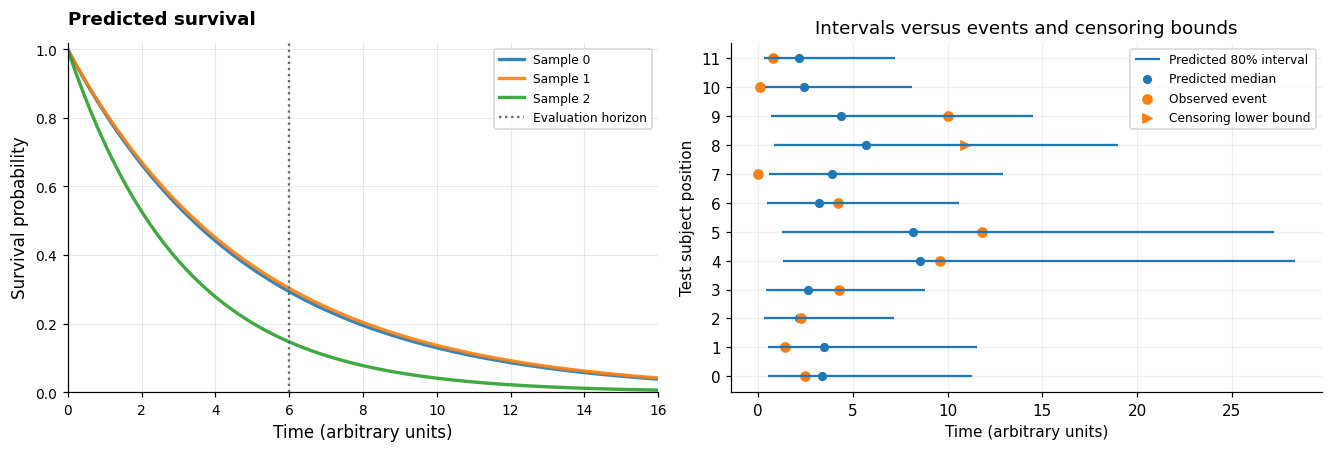

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
evaluator.plot_survival_curves(
    [0, 1, 2], ax=axes[0], x_lim=(0, follow_up), x_label="Time (arbitrary units)"
)
axes[0].axvline(horizon, color="0.4", linestyle=":", label="Evaluation horizon")
axes[0].legend(fontsize=8)
positions = np.arange(12)
axes[1].hlines(
    positions,
    intervals[:12, 0],
    intervals[:12, 1],
    color="C0",
    label="Predicted 80% interval",
)
axes[1].scatter(
    point_summaries["Median"].iloc[:12],
    positions,
    color="C0",
    s=25,
    label="Predicted median",
)
for event, marker, label in [
    (True, "o", "Observed event"),
    (False, ">", "Censoring lower bound"),
]:
    selected = test_events[:12] == event
    axes[1].scatter(
        test_times[:12][selected],
        positions[selected],
        marker=marker,
        color="C1",
        label=label,
    )
axes[1].set(
    xlabel="Time (arbitrary units)",
    ylabel="Test subject position",
    title="Intervals versus events and censoring bounds",
    yticks=positions,
)
axes[1].legend(fontsize=8)
plt.show()

## 3. Discrimination: static concordance

Static concordance ranks the configured predicted event times. **Longer predicted time
means lower risk**; do not negate these times when passing them to `PointEvaluator`.

- **Harrell:** observed-event anchors compared with later observed outcomes.
  `Naive` is an alias.
- **Uno / IPCW:** comparable-pair counts weighted using a training-based censoring model.
  `IPCW` is an alias of `Uno`.
- **Margin:** uses training-KM-based guesses for censored event times to construct pairs.

`tau=6` keeps anchors or effective earlier times strictly before 6; omitting `tau` removes
this cutoff. `ties="Risk"` gives half credit to prediction ties and excludes event-time
ties. Other policies are `None`, `Time`, and `All`. Higher is better; roughly 0.5 indicates
chance ordering. IPCW assumes an appropriate censoring model and positive required weights.

In [6]:
static_rows = []
for method in ["Harrell", "Uno", "Margin"]:
    score, concordant, comparable = evaluator.concordance(
        method=method, ties="Risk", tau=horizon
    )
    static_rows.append(
        {
            "Method": method,
            "C-index": score,
            "Concordant count / weight": concordant,
            "Comparable count / weight": comparable,
        }
    )
static_concordance = pd.DataFrame(static_rows).set_index("Method")
np.testing.assert_allclose(
    evaluator.concordance(method="Harrell", tau=horizon),
    evaluator.concordance(method="Naive", tau=horizon),
)
np.testing.assert_allclose(
    evaluator.concordance(method="Uno", tau=horizon),
    evaluator.concordance(method="IPCW", tau=horizon),
)
static_concordance

,C-index,Concordant count / weight,Comparable count / weight
Method,,,
Harrell,0.618861,114509.000000,185032.000000
Uno,0.621574,132295.027164,212838.633514
Margin,0.617616,116981.874661,189408.838409


## 4. Discrimination: time-dependent concordance

Time-dependent concordance evaluates each curve at event-anchor times rather than
reducing it to one predicted time. `risks="Survival"` ranks by `-S(t)`; `risks="Hazard"`
ranks by interval hazard rates estimated from the supplied survival grid. Larger values
of either risk representation indicate higher risk.

`method="Antolini"` uses observable comparable pairs; `Naive` is its alias.
`method="IPCW"` adds training-based censoring weights. The IPCW hazard option implements
the Gandy–Matcham approach. The risk representation matters particularly when hazard
rankings change over time. This exponential example has no crossing risk rankings, so
it does not illustrate that distinction. We keep the same `tau=6` cutoff throughout.

In [7]:
hazards = evaluator.predict_multi_hazards_from_curve(selected_times)
np.testing.assert_allclose(
    hazards, np.broadcast_to(fitted_rates[:, None], hazards.shape), atol=1e-12
)
time_dependent_rows = []
for method in ["Antolini", "IPCW"]:
    for risk_type in ["Survival", "Hazard"]:
        score, concordant, comparable = evaluator.concordance_time_dependent(
            method=method, risks=risk_type, ties="Risk", tau=horizon
        )
        time_dependent_rows.append(
            {
                "Method": method,
                "Risks": risk_type,
                "C-index": score,
                "Concordant count / weight": concordant,
                "Comparable count / weight": comparable,
            }
        )
np.testing.assert_allclose(
    evaluator.concordance_time_dependent(method="Antolini", tau=horizon),
    evaluator.concordance_time_dependent(method="Naive", tau=horizon),
)
pd.DataFrame(time_dependent_rows).set_index(["Method", "Risks"])

C-index  Concordant count / weight  \
Method   Risks                                           
Antolini Survival  0.618861              114509.000000   
         Hazard    0.618861              114509.000000   
IPCW     Survival  0.621574              132295.027164   
         Hazard    0.621574              132295.027164   

                   Comparable count / weight  
Method   Risks                                
Antolini Survival              185032.000000  
         Hazard                185032.000000  
IPCW     Survival              212838.633514  
         Hazard                212838.633514

## 5. Discrimination: time-dependent AUC / AUROC

At time 6, cases are observed events at or before the horizon. Controls are subjects
observed beyond it, including censorings exactly at the horizon. Earlier censorings have
unknown status. `Naive` excludes those subjects without weighting; `IPCW` weights cases
using the training censoring estimate. `auroc` is an alias of `auc`.

AUC measures case/control separation at one horizon, while concordance uses event-time
ordering. Neither evaluates whether the numerical probabilities are accurate.

In [8]:
auc_scores = {
    method: evaluator.auc(target_time=horizon, method=method)
    for method in ["Naive", "IPCW"]
}
np.testing.assert_allclose(
    auc_scores["IPCW"], evaluator.auroc(target_time=horizon, method="IPCW")
)
pd.Series(auc_scores, name="AUC at time 6")

Naive    0.734140
IPCW     0.732774
Name: AUC at time 6, dtype: float64

## 6. Probability prediction error: Brier scores and IBS

The Brier score compares predicted survival with the indicator of being event-free.
IPCW estimates squared probability error despite censoring, using reverse KM on training
outcomes. The implementation uses left limits $G(t-)$ at censoring jumps; see the
[reverse-KM notebook](Reverse_Kaplan_Meier_IPCW.ipynb) for tie conventions.

With `IPCW_weighted=False`, earlier censored observations contribute zero while the
denominator remains the full sample size. On censored data this is not a censoring-adjusted
risk estimate and should not be compared with IPCW as though they target the same quantity.
Fully observed data use plain scoring automatically.

`brier_score_multiple_points` returns a score curve. IBS integrates it over the explicit
**[0, 6]** interval and divides by its length. Lower is better; changing the grid or
integration interval changes the comparison. We use the trapezoidal rule, with Simpson's
rule also available through `integration_method="simpson"`.

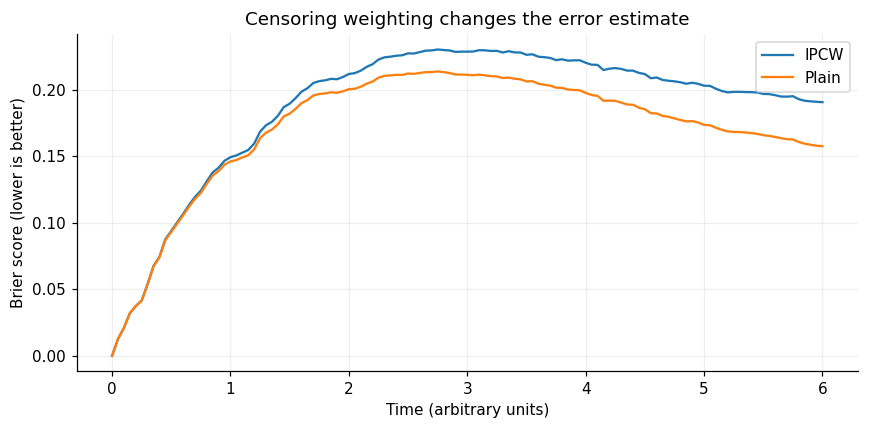

,Brier at 6,"IBS [0, 6]"
Plain,0.157520,0.171496
IPCW,0.190573,0.188235


In [9]:
integration_grid = np.linspace(0, horizon, 121)
brier_results = {}
for weighted in [False, True]:
    curve = evaluator.brier_score_multiple_points(
        integration_grid, IPCW_weighted=weighted
    )
    single = evaluator.brier_score(target_time=horizon, IPCW_weighted=weighted)
    ibs = evaluator.integrated_brier_score(
        target_times=integration_grid, IPCW_weighted=weighted
    )
    np.testing.assert_allclose(single, curve[-1])
    np.testing.assert_allclose(ibs, trapezoid(curve, integration_grid) / horizon)
    brier_results["IPCW" if weighted else "Plain"] = {
        "Brier at 6": single,
        "IBS [0, 6]": ibs,
    }
fig, ax = plt.subplots()
for name, weighted in [("IPCW", True), ("Plain", False)]:
    ax.plot(
        integration_grid,
        evaluator.brier_score_multiple_points(integration_grid, IPCW_weighted=weighted),
        label=name,
    )
ax.set(
    xlabel="Time (arbitrary units)",
    ylabel="Brier score (lower is better)",
    title="Censoring weighting changes the error estimate",
)
ax.legend()
fig.tight_layout()
plt.show()
pd.DataFrame(brier_results).T

## 7. Event-time prediction errors: all six censoring methods

MAE, MSE, and RMSE evaluate the configured **median** predictions here. Their units are
time, squared time, and time respectively. Each censoring method has a different
construction; lower numbers across different rows do not establish that one is a better
estimator of prediction error.

| Method | Treatment of censoring |
| --- | --- |
| `Uncensored` | Uses observed-event subjects only; their errors need not represent the whole cohort |
| `Hinge` | Penalizes an observed event's error and a censored subject's prediction only when earlier than censoring |
| `Margin` | Uses training-KM conditional mean guesses for censored event times |
| `IPCW-T` | Uses the mean of strictly later observed training events as a surrogate; omits censorings with no such event |
| `IPCW-D` | Applies inverse censoring weights to observed-event errors, normalized over observed-event subjects |
| `Pseudo_obs` | Uses training-KM pseudo-observations as surrogate event times |

For `weighted=None`, the evaluator defaults to no extra weighting for Uncensored/Hinge
and weighting for the other methods. Margin, IPCW-T, and Pseudo_obs downweight censored
subjects using training KM; IPCW-D always applies its censoring weights. We show that
default explicitly through the same argument below. KM-based guesses can depend on tail
assumptions; a parametric prediction model does not remove those estimator assumptions.

In [10]:
error_methods = ["Uncensored", "Hinge", "Margin", "IPCW-T", "IPCW-D", "Pseudo_obs"]
error_rows = []
for method in error_methods:
    mae = evaluator.mae(method=method, weighted=None)
    mse = evaluator.mse(method=method, weighted=None)
    rmse = evaluator.rmse(method=method, weighted=None)
    np.testing.assert_allclose(rmse, np.sqrt(mse))
    error_rows.append({"Method": method, "MAE": mae, "MSE": mse, "RMSE": rmse})
error_table = pd.DataFrame(error_rows).set_index("Method")
assert np.isfinite(error_table.to_numpy()).all()
no_later_event = (~test_events) & (test_times >= train_times[train_events].max())
print(
    f"IPCW-T omits {no_later_event.sum()} censorings without a strictly later training event."
)
error_table

IPCW-T omits 33 censorings without a strictly later training event.


,MAE,MSE,RMSE
Method,,,
Uncensored,2.673348,12.076647,3.475147
Hinge,2.734382,15.280566,3.909037
Margin,3.320998,19.772248,4.446600
IPCW-T,2.814248,13.487122,3.672482
IPCW-D,3.304527,15.708000,3.963332
Pseudo_obs,3.617786,26.952742,5.191603


### Log errors, weighting, and truncation

`log_scale=True` compares log-times, changing the error's units and emphasis toward
relative timing. It requires positive relevant times. `weighted=True` enables the
optional Hinge weighting. `truncated_time=6` clips predictions and surrogate/event times
for supported methods; it changes the error target and does not change the prediction
model. The truncated Margin example therefore concerns a different target from the full
time errors above.

In [11]:
pd.Series(
    {
        "Hinge MAE, weighted": evaluator.mae(method="Hinge", weighted=True),
        "Hinge MAE, log-time scale": evaluator.mae(method="Hinge", log_scale=True),
        "Hinge MSE, log-time scale": evaluator.mse(method="Hinge", log_scale=True),
        "Margin MAE, times capped at 6": evaluator.mae(
            method="Margin", truncated_time=horizon
        ),
    },
    name="Value",
)

Hinge MAE, weighted              2.966375
Hinge MAE, log-time scale        0.852392
Hinge MSE, log-time scale        1.639871
Margin MAE, times capped at 6    1.807056
Name: Value, dtype: float64

## 8. Fixed-time calibration: grouped one-calibration

Groups compare mean predicted **event risk**, `1 - S(6)`, with observed event incidence.
`method="DN"` uses within-group Kaplan–Meier incidence. `adjust_variance=True` uses
Greenwood variance; `False` uses expected binomial variance and the original DN convention.
`method="Uncensored"` excludes censorings before the horizon and uses remaining binary
outcomes; that selection can distort incidence when censoring is present.

`binning_strategy="C"` forms approximately equal-sized risk groups; `"H"` instead uses
equal-width probability groups. The plots use five C groups. Points above the diagonal
indicate underpredicted event risk; points below it indicate overprediction.

A small p-value suggests a departure. A large p-value means the test did not detect one,
**not proof of calibration**. Zero estimated group variance makes the adjusted p-value
undefined. Grouping, horizon, and sample size all affect the diagnostic.

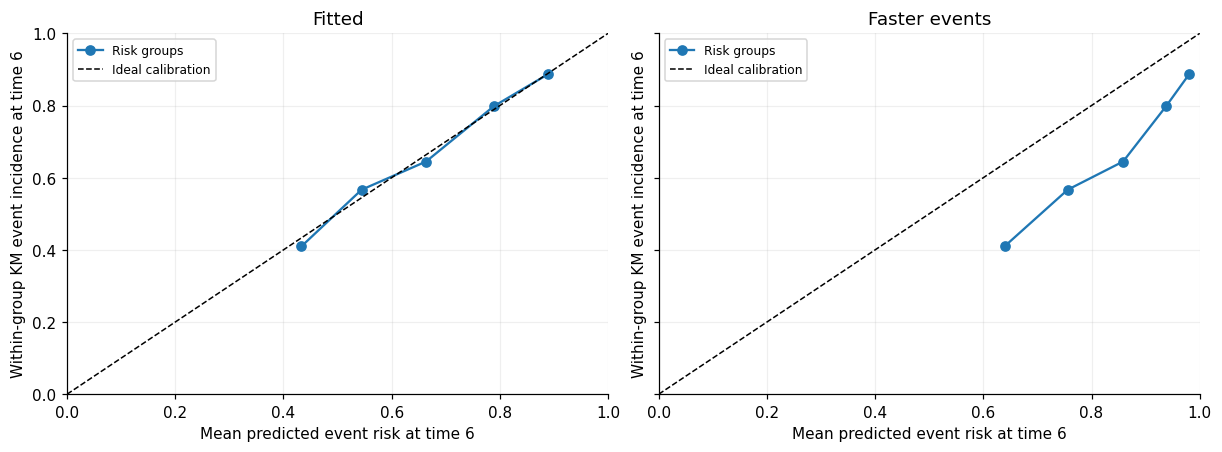

p-value
Model         Method     Adjusted variance              
Fitted        DN         True               9.788533e-01
                         False              9.254847e-01
              Uncensored True               4.895648e-01
Faster events DN         True               3.567205e-18
                         False              7.297105e-47
              Uncensored True               7.265691e-13

In [12]:
one_results = {}
test_rows = []
fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), sharex=True, sharey=True, constrained_layout=True
)
for ax, (name, current) in zip(axes, evaluators.items()):
    for method, adjusted in [("DN", True), ("DN", False), ("Uncensored", True)]:
        p_value, observed, predicted = current.one_calibration(
            target_time=horizon,
            num_bins=5,
            binning_strategy="C",
            method=method,
            adjust_variance=adjusted,
        )
        test_rows.append(
            {
                "Model": name,
                "Method": method,
                "Adjusted variance": adjusted,
                "p-value": p_value,
            }
        )
        if method == "DN" and adjusted:
            one_results[name] = p_value
            order = np.argsort(predicted)
            ax.plot(
                np.asarray(predicted)[order],
                np.asarray(observed)[order],
                "o-",
                label="Risk groups",
            )
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Ideal calibration")
    ax.set(
        xlabel="Mean predicted event risk at time 6",
        ylabel="Within-group KM event incidence at time 6",
        title=name,
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.legend(fontsize=8)
plt.show()
pd.DataFrame(test_rows).set_index(["Model", "Method", "Adjusted variance"])

## 9. Fixed-time smooth calibration: ICI

Austin et al.'s single-event ICI fits a Cox calibration model with a restricted cubic
spline of complementary log-log transformed predicted event risk. This differs from the
Fine–Gray calibration fit in the [competing risks notebook](CompetingRisks_Example.ipynb).
The fitted calibration curve is estimated from test outcomes to diagnose their predictions;
it does not update the original model. Here `knots=3` is the total spline knot count.

ICI, E50, E90, and E_max summarize the mean, median, 90th percentile, and maximum absolute
differences between predicted and smoothed calibrated risks across the subjects. All are
**probability errors**, not p-values. The displayed curve spans the first to 99th risk
percentiles; its uncertainty and smoothing choices matter, especially with small samples.

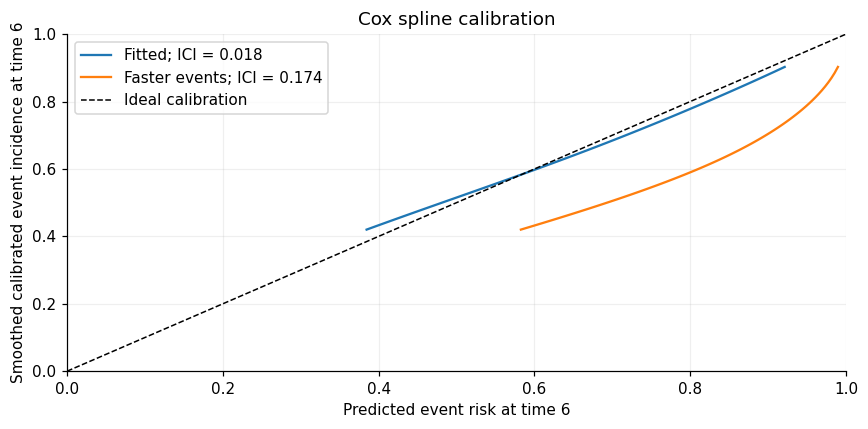

,ICI,E50,E90,E_max
Fitted,0.017613,0.019405,0.027257,0.037363
Faster events,0.174251,0.187437,0.209603,0.210546


In [13]:
ici_results = {}
fig, ax = plt.subplots()
for name, current in evaluators.items():
    summary = current.integrated_calibration_index(
        target_time=horizon, knots=3, draw_figure=False
    )
    ici_results[name] = {
        metric: float(summary[metric]) for metric in ["ICI", "E50", "E90", "E_max"]
    }
    ax.plot(
        summary["curve"]["grid"],
        summary["curve"]["cal_pred"],
        label=f"{name}; ICI = {summary['ICI']:.3f}",
    )
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Ideal calibration")
ax.set(
    xlabel="Predicted event risk at time 6",
    ylabel="Smoothed calibrated event incidence at time 6",
    title="Cox spline calibration",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend()
fig.tight_layout()
plt.show()
pd.DataFrame(ici_results).T

## 10. Distributional calibration: D and K-S D-calibration

D-calibration uses each subject's predicted survival at its observed time. An event
contributes to one survival-probability bin; a censored observation distributes its
contribution over the possible probability range. The histogram is compared with uniform
allocation using a chi-squared statistic. The default ten bins are used here.

K-S D-calibration transforms the observed survival probabilities to CDF probabilities
`F(t) = 1 - S(t)` and fits Kaplan–Meier on that scale. A right-censored event time
implies a right-censored CDF probability: if `T > C`, then `F(T) >= F(C)`.
The estimated step CDF is completed with endpoints (0, 0) and (1, 1), placing any
remaining mass at 1, and compared with the uniform identity without histogram bins.
Returned curve data and plots use CDF probabilities; inputs remain survival probabilities.

The method returns the maximum vertical deviation and an approximate bootstrap p-value.
Each null sample draws uniform event probabilities and independent censoring probabilities
from reverse KM, with remaining censoring mass placed at 1. The same endpoint convention
is used for observed and simulated curves. This assumes independent censoring on the
transformed probability scale and treats predictions as fixed. Here, 999 resamples give
a minimum p-value of 0.001; `seed=42` makes the results reproducible. Increase `n_resamples`
for finer p-value resolution. This test and binned D-calibration handle censoring differently.

For either diagnostic, inspect effect sizes and curves rather than reducing the analysis
to a significance threshold. Unlike one-calibration and ICI, these examine the predicted
distribution rather than only the chosen time horizon.

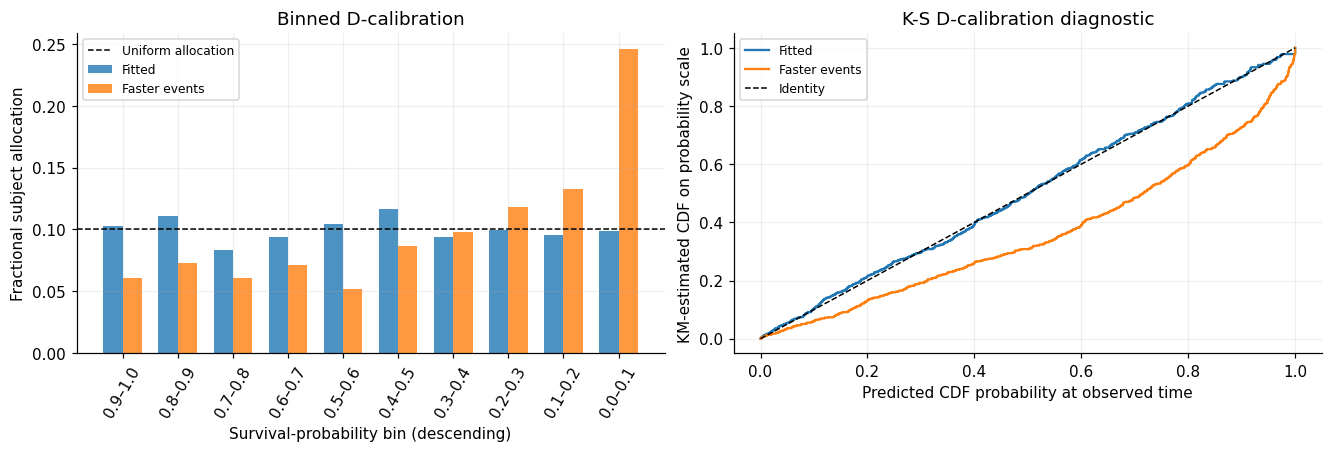

,D p-value,KS statistic,KS bootstrap p-value
Fitted,7.895445e-01,0.023548,0.928
Faster events,3.300862e-40,0.220693,0.001


In [14]:
distribution_results = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
bin_positions = np.arange(10)
for offset, (name, current) in enumerate(evaluators.items()):
    d_p, histogram = current.d_calibration(num_bins=10)
    ks_p, ks_details = current.ksd_calibration(return_details=True, n_resamples=999, seed=42)
    plt.close(
        ks_details["figure"][0]
    )  # Reuse returned curve data in this comparison layout.
    distribution_results[name] = {
        "D p-value": d_p,
        "KS statistic": ks_details["statistics"],
        "KS bootstrap p-value": ks_p,
    }
    axes[0].bar(
        bin_positions + (offset - 0.5) * 0.35,
        histogram / n_test,
        width=0.35,
        label=name,
        alpha=0.8,
    )
    support, cdf = ks_details["empirical_distribution"]
    axes[1].step(support, cdf, where="post", label=name)
axes[0].axhline(
    0.1, color="black", linestyle="--", linewidth=1, label="Uniform allocation"
)
axes[0].set(
    xticks=bin_positions,
    xticklabels=[f"{(9 - i) / 10:.1f}–{(10 - i) / 10:.1f}" for i in bin_positions],
    xlabel="Survival-probability bin (descending)",
    ylabel="Fractional subject allocation",
    title="Binned D-calibration",
)
axes[0].tick_params(axis="x", labelrotation=60)
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="Identity")
axes[1].set(
    xlabel="Predicted CDF probability at observed time",
    ylabel="KM-estimated CDF on probability scale",
    title="K-S D-calibration diagnostic",
)
for ax in axes:
    ax.legend(fontsize=8)
plt.show()
pd.DataFrame(distribution_results).T

## 11. Marginal calibration: average predicted survival versus KM

KM calibration compares the mean predicted survival with the test cohort's marginal KM
estimate. This implementation integrates squared differences on observed-event times and
divides by the final observed-event time; it does not take a square root. Independent
censoring supports the marginal KM reference. The score is an error, not a p-value.

The score's interval is determined by observed events, whereas the illustration below is
drawn on the prediction grid through follow-up. Good agreement of averages can conceal
subject-level or subgroup errors. The long model tail beyond follow-up is not validated
by this marginal comparison.

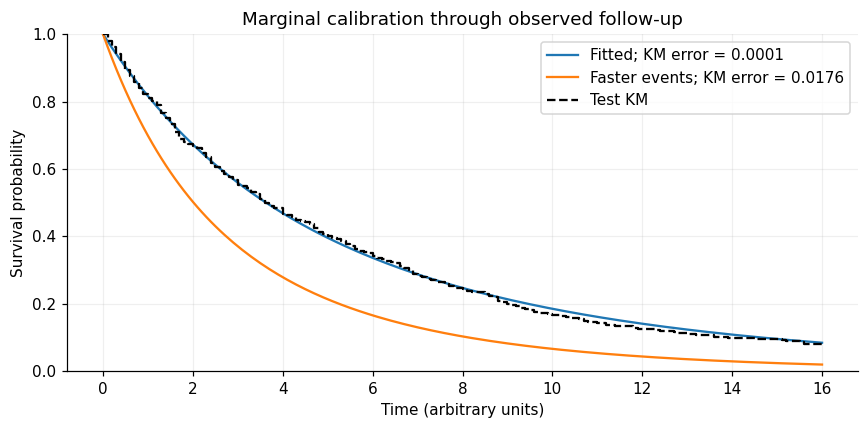

KM error integrates through the last observed event: 15.577


In [15]:
km_scores = {}
marginal_km = KaplanMeier(test_times, test_events)
display_times = prediction_grid[prediction_grid <= follow_up]
fig, ax = plt.subplots()
for name, current in evaluators.items():
    km_scores[name] = current.km_calibration()
    mean_survival = current.predict_multi_probabilities_from_curve(display_times).mean(
        axis=0
    )
    ax.plot(
        display_times, mean_survival, label=f"{name}; KM error = {km_scores[name]:.4f}"
    )
ax.step(
    display_times,
    marginal_km.predict(display_times),
    where="post",
    color="black",
    linestyle="--",
    label="Test KM",
)
ax.set(
    xlabel="Time (arbitrary units)",
    ylabel="Survival probability",
    title="Marginal calibration through observed follow-up",
    ylim=(0, 1),
)
ax.legend()
fig.tight_layout()
plt.show()
print(
    f"KM error integrates through the last observed event: {test_times[test_events].max():.3f}"
)

## 12. Residual diagnostics: five definitions

At each observed time $Y_i$, write $r_i=-\log\widehat S(Y_i)$ and let $\delta_i$ indicate
an event. All definitions below are available through `residuals(method=...)`.

| Method | Definition / adjustment |
| --- | --- |
| `CoxSnell` | Cumulative hazard $r_i$; latent, fully observed residuals have a unit exponential reference under a correct continuous model |
| `Modified CoxSnell-v1` | Adds 1 to censored residuals, using a mean excess adjustment |
| `Modified CoxSnell-v2` | Adds $\log 2$ to censored residuals, using a median excess adjustment |
| `Martingale` | $\delta_i-r_i$ |
| `Deviance` | Signed deviance transformation of the martingale residual |

Observed Cox–Snell residuals remain censored when the original observations are censored.
Their empirical cumulative hazard should be near the identity under a correct model.
Simply plotting their uncensored histogram against an exponential density would ignore
this censoring. Martingale/deviance patterns against a feature may reveal misspecification;
no single residual plot establishes goodness of fit.

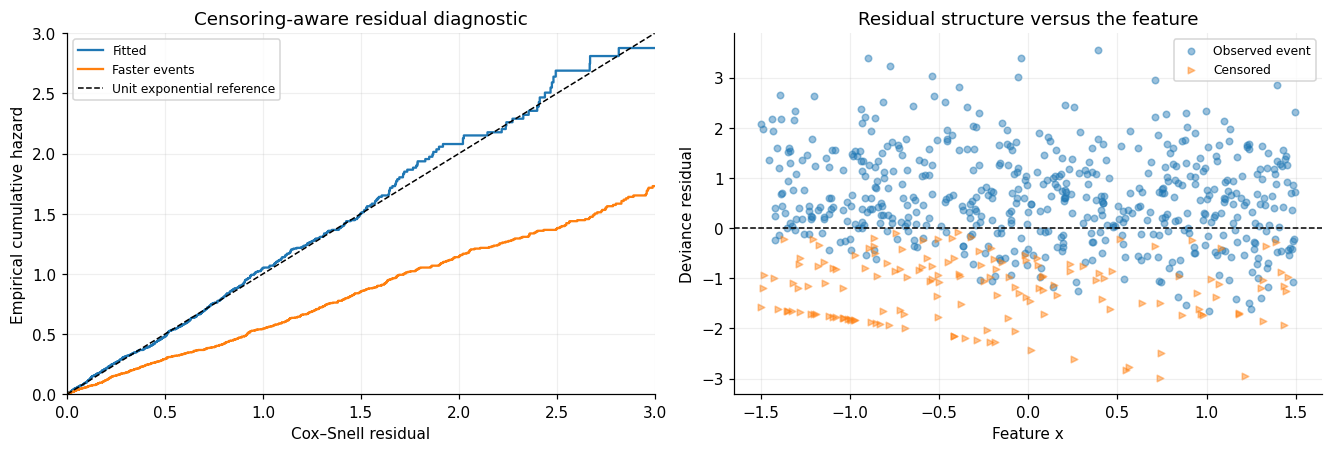

,mean,std,min,max
CoxSnell,0.768515,0.725059,0.000665,4.451150
Modified CoxSnell-v1,0.988515,0.881480,0.000665,5.451150
Modified CoxSnell-v2,0.921008,0.814460,0.000665,5.144297
Martingale,0.011485,0.881480,-4.451150,0.999335
Deviance,0.213601,1.150916,-2.983672,3.554213


In [16]:
residual_methods = [
    "CoxSnell",
    "Modified CoxSnell-v1",
    "Modified CoxSnell-v2",
    "Martingale",
    "Deviance",
]
residual_values = pd.DataFrame(
    {method: evaluator.residuals(method=method) for method in residual_methods}
)
assert np.isfinite(residual_values.to_numpy()).all()
np.testing.assert_allclose(
    residual_values["CoxSnell"], -np.log(survival_at_observed_times)
)
np.testing.assert_allclose(
    residual_values["Martingale"], test_events - residual_values["CoxSnell"]
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, current in evaluators.items():
    residual = current.residuals(method="CoxSnell")
    empirical_hazard = NelsonAalen(residual, test_events)
    axes[0].step(
        empirical_hazard.survival_times,
        empirical_hazard.cumulative_hazard,
        where="post",
        label=name,
    )
axes[0].plot([0, 3], [0, 3], "k--", linewidth=1, label="Unit exponential reference")
axes[0].set(
    xlabel="Cox–Snell residual",
    ylabel="Empirical cumulative hazard",
    title="Censoring-aware residual diagnostic",
    xlim=(0, 3),
    ylim=(0, 3),
)
axes[0].legend(fontsize=8)
for event, marker, label in [(True, "o", "Observed event"), (False, ">", "Censored")]:
    selected = test_events == event
    axes[1].scatter(
        x_test[selected, 0],
        residual_values.loc[selected, "Deviance"],
        s=18,
        alpha=0.45,
        marker=marker,
        label=label,
    )
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(
    xlabel="Feature x",
    ylabel="Deviance residual",
    title="Residual structure versus the feature",
)
axes[1].legend(fontsize=8)
plt.show()
residual_values.describe().T[["mean", "std", "min", "max"]]

## 13. Other distribution diagnostics: Survival-AUPRC

`auprc(n_quad=256)` is a survival-distribution score; it is not the usual binary
classification precision-recall AUC at time 6. It integrates probability mass around
observed event times, and uses a right-censoring contribution for censored subjects.
Higher is better under this score. `n_quad` controls the quadrature resolution.

Its CDF interpolation uses a value of one beyond the supplied time grid. The example's
long model grid makes its remaining tail mass small; on a short grid, that boundary
convention can materially affect this score.

In [17]:
auprc_scores = {name: current.auprc(n_quad=256) for name, current in evaluators.items()}
pd.Series(auprc_scores, name="Survival-AUPRC")

Fitted           0.454098
Faster events    0.426720
Name: Survival-AUPRC, dtype: float64

## 14. Other standalone diagnostics: quantile calibration slope and sharpness

`calibration_slope_right_censor` takes a **CDF**, `1 - survival`, and constructs observed
event proportions at individual predicted quantiles, then fits a slope through the origin.
It keeps all observed events and censorings beyond the predicted quantile, omitting earlier
censorings. Those are available-outcome proportions, not an IPCW correction: censoring
selection can shift this diagnostic even for a well-specified model. It is distinct from
a Cox calibration slope or the grouped fixed-time one-calibration fit.

`cov` is the event-time coefficient of variation, standard deviation divided by mean.
It uses CDF increments on the supplied grid and normalizes their represented mass, so a
finite grid yields a **conditional-on-grid** sharpness diagnostic. It uses no outcomes.
Low spread alone is not evidence of accuracy; sharpness should be considered alongside
calibration. Full exponential distributions have CoV=1 regardless of their rate.

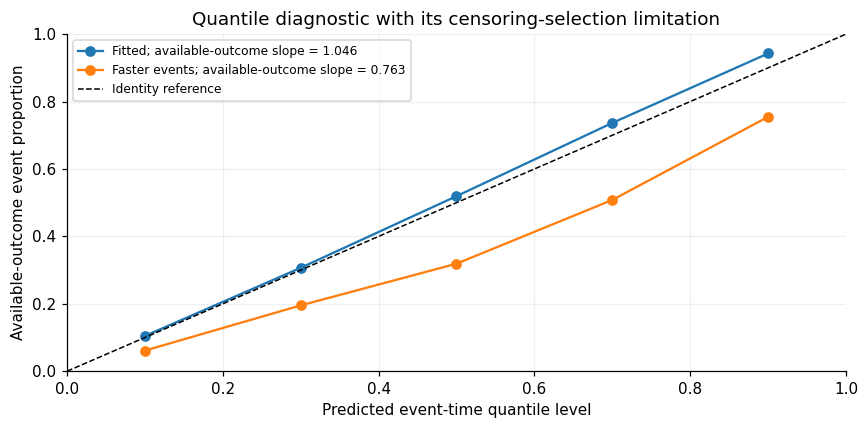

,Quantile calibration slope,Mean conditional-on-grid CoV,Mean survival beyond time 80
Model,,,
Fitted,1.046189,0.997111,1.431755e-04
Faster events,0.762992,0.999750,5.368879e-07


In [18]:
standalone_rows = []
fig, ax = plt.subplots()
for name, current in evaluators.items():
    predicted_cdf = 1 - current.pred_survs
    levels, observed_proportions, slope = calibration_slope_right_censor(
        test_events,
        test_times,
        predicted_cdf,
        prediction_grid,
        ps=(0.1, 0.3, 0.5, 0.7, 0.9),
        quantile_method="Linear",
        through_origin=True,
    )
    mean_cov, per_subject_cov = cov(predicted_cdf, prediction_grid, return_details=True)
    ax.plot(
        levels,
        observed_proportions,
        "o-",
        label=f"{name}; available-outcome slope = {slope:.3f}",
    )
    standalone_rows.append(
        {
            "Model": name,
            "Quantile calibration slope": slope,
            "Mean conditional-on-grid CoV": mean_cov,
            "Mean survival beyond time 80": current.pred_survs[:, -1].mean(),
        }
    )
    np.testing.assert_allclose(mean_cov, per_subject_cov.mean())
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Identity reference")
ax.set(
    xlabel="Predicted event-time quantile level",
    ylabel="Available-outcome event proportion",
    title="Quantile diagnostic with its censoring-selection limitation",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
pd.DataFrame(standalone_rows).set_index("Model")

## 15. Other metrics: log-rank comparison

`log_rank` compares observed follow-up with the model's predicted event times, treating
the latter as fully observed. Weighted variants include Wilcoxon, Tarone–Ware, Peto, and
Fleming–Harrington. We illustrate the default and Wilcoxon weighting.

This is a distribution-level diagnostic, not a test of individual prediction accuracy.
In this use, both collections belong to the same subjects, so a standard independent-group
p-value interpretation is limited. Also, a distribution of predicted medians need not
match the population distribution of realized event times, even for calibrated curves.

In [19]:
logrank_rows = []
for name, current in evaluators.items():
    for weighting in [None, "wilcoxon"]:
        p_value, statistic = current.log_rank(weightings=weighting)
        logrank_rows.append(
            {
                "Model": name,
                "Weighting": weighting or "Unweighted",
                "Statistic": statistic,
                "Descriptive p-value": p_value,
            }
        )
pd.DataFrame(logrank_rows).set_index(["Model", "Weighting"])

Statistic  Descriptive p-value
Model         Weighting                                  
Fitted        Unweighted   34.309558         4.700675e-09
              wilcoxon      5.447064         1.960124e-02
Faster events Unweighted  246.076644         1.861201e-55
              wilcoxon     72.215246         1.929593e-17

## 16. Choose the evaluator that matches the prediction output

A full curve supports all the metrics above. If a model supplies only a point time,
use `PointEvaluator`; if it supplies only `S(6)`, use `SingleTimeEvaluator`. They expose
the corresponding subsets without inventing a full distribution. The checks below verify
agreement when the same predictions are extracted from our fitted curves.

`LifelinesEvaluator`, `PycoxEvaluator`, `ScikitSurvivalEvaluator`, and `QuantileRegEvaluator`
adapt other prediction formats to the survival-curve metrics. The model-specific examples
explain fitting and prediction orientation; this notebook concentrates on the metrics.

In [20]:
point_evaluator = PointEvaluator(
    evaluator.predicted_event_times, test_times, test_events, train_times, train_events
)
single_time_evaluator = SingleTimeEvaluator(
    survival_at_horizon,
    test_times,
    test_events,
    target_time=horizon,
    train_event_times=train_times,
    train_event_indicators=train_events,
)
np.testing.assert_allclose(
    point_evaluator.concordance(tau=horizon), evaluator.concordance(tau=horizon)
)
np.testing.assert_allclose(
    point_evaluator.mae(method="Hinge"), evaluator.mae(method="Hinge")
)
np.testing.assert_allclose(
    single_time_evaluator.auc(method="IPCW"),
    evaluator.auc(target_time=horizon, method="IPCW"),
)
np.testing.assert_allclose(
    single_time_evaluator.brier_score(), evaluator.brier_score(target_time=horizon)
)
print(
    "Point and single-time metrics agree with their corresponding survival-curve predictions."
)

Point and single-time metrics agree with their corresponding survival-curve predictions.


## 17. Read the results together

The distortion preserves risk ordering, so concordance and AUC can remain identical
while probability errors and calibration departures change. D-test p-values are not
scores to maximize, and residuals, sharpness, and log-rank comparisons provide different
diagnostics rather than interchangeable accuracy measures.

This is one reproducible split, not an uncertainty analysis. In a real comparison, fix
the point summary, horizons, integration interval, censoring method, and tie policy before
comparing models. Use repeated resampling or external validation for uncertainty and
inspect subgroup calibration rather than relying only on marginal summaries.

In [21]:
comparison_rows = []
for name, current in evaluators.items():
    comparison_rows.append(
        {
            "Model": name,
            "Uno concordance, tau=6 ↑": current.concordance(method="Uno", tau=horizon)[
                0
            ],
            "IPCW AUC at 6 ↑": current.auc(target_time=horizon, method="IPCW"),
            "IPCW Brier at 6 ↓": current.brier_score(target_time=horizon),
            "IPCW IBS [0, 6] ↓": current.integrated_brier_score(
                target_times=integration_grid
            ),
            "MAE-Hinge ↓": current.mae(method="Hinge"),
            "ICI at 6 ↓": ici_results[name]["ICI"],
            "KM squared error ↓": km_scores[name],
            "Survival-AUPRC ↑": auprc_scores[name],
        }
    )
comparison = pd.DataFrame(comparison_rows).set_index("Model")
assert np.isfinite(comparison.to_numpy()).all()
np.testing.assert_allclose(comparison.iloc[0, :2], comparison.iloc[1, :2])
comparison.T

Model,Fitted,Faster events
"Uno concordance, tau=6 ↑",0.621574,0.621574
IPCW AUC at 6 ↑,0.732774,0.732774
IPCW Brier at 6 ↓,0.190573,0.222784
"IPCW IBS [0, 6] ↓",0.188235,0.215554
MAE-Hinge ↓,2.734382,2.982771
ICI at 6 ↓,0.017613,0.174251
KM squared error ↓,0.000121,0.017558
Survival-AUPRC ↑,0.454098,0.426720


## References and related examples

- Harrell et al. (1996), [concordance and prognostic model evaluation](https://doi.org/10.1002/(SICI)1097-0258(19960229)15:4%3C361::AID-SIM168%3E3.0.CO;2-4).
- Uno et al. (2011), [censoring-weighted concordance](https://doi.org/10.1002/sim.4154).
- Antolini et al. (2005), [time-dependent discrimination](https://doi.org/10.1002/sim.2427).
- Gandy and Matcham (2025), [concordance with crossing hazards](https://doi.org/10.1111/sjos.70000).
- Qi et al. (2023), [event-time error estimation with censoring](https://proceedings.mlr.press/v202/qi23b.html).
- Haider et al. (2020), [individual survival distribution evaluation and D-calibration](https://www.jmlr.org/papers/v21/18-772.html).
- Austin et al. (2020), [calibration curves and ICI for survival models](https://doi.org/10.1002/sim.8570).
- Avati et al. (2020), [sharp and calibrated survival predictions](https://proceedings.mlr.press/v115/avati20a.html).
- [Out-of-fold calibration](Calibration_for_CrossValidation_Example.ipynb) and
  [competing risks metrics](CompetingRisks_Example.ipynb) extend the workflows here.